# What Does a Fresher Need to Land a Data Analyst Job in India?
### Job-market analysis of 5,000 Indian tech postings (June 2024 – April 2026)

**Objective:** use job-posting data to answer practical questions for an aspiring Data Analyst:

1. Which skills do Data Analyst employers ask for, and which matter most for freshers?
2. What does Data Analyst pay look like, and how does it grow with experience?
3. Does knowing a particular skill actually lead to higher pay?
4. Where are the jobs, and in which work modes?
5. How has hiring changed over time?
6. How competitive are the postings?

**Data:** public Kaggle dataset of Indian tech job postings (17 columns). Cleaning is done by `src/data_cleaning.py`; reusable analysis and chart code lives in `src/analysis.py`. This notebook tells the story on top of them.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Works whether the notebook is opened from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as an

pd.set_option("display.float_format", "{:.1f}".format)
an._setup_style()

df = an.load_clean()
da = an.data_analyst_subset(df)
fresher_da = da[da["experience_group"] == "Fresher"]
print(f"Project root: {ROOT}")

Project root: C:\data-analyst-job-market-analysis


## 2. Data overview

In [2]:
print(f"Postings: {len(df):,}  |  Columns: {df.shape[1]}")
print(f"Date range: {df['date_posted'].min().date()} to {df['date_posted'].max().date()}")
print(f"Missing values in raw columns: {int(df.iloc[:, :17].isna().sum().sum())}")
df.head(3)

Postings: 5,000  |  Columns: 26
Date range: 2024-06-01 to 2026-04-30
Missing values in raw columns: 0


,job_id,job_title,company,company_type,industry,city,location_tier,experience_level,job_type,work_mode,...,date_posted,experience_group,applicants_per_opening,year,month,year_month,skill_count,is_data_analyst,salary_outlier,skills_list
0,IND2025000,Android Developer,Tech Mahindra,MNC,Information Technology,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,...,2025-10-31,Senior,92.0,2025,10,2025-10,3,False,False,"[Kotlin, Java, REST APIs]"
1,IND2025001,QA Engineer,Dream11,Indian Unicorn,Information Technology,Lucknow,Tier 2,Senior (6-10 yrs),Full-Time,Hybrid,...,2025-05-19,Senior,108.3,2025,5,2025-05,5,False,False,"[Selenium, Manual Testing, Postman, API Testin..."
2,IND2025002,Business Analyst,HAL,PSU/Govt,EdTech,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,...,2024-08-21,Senior,111.8,2024,8,2024-08,3,False,False,"[JIRA, Excel, Power BI]"


### Scope: how "Data Analyst" is defined

A posting counts as a Data Analyst role only if its **job title contains "Data Analyst"**. Related titles (e.g. Business Analyst) are deliberately excluded to keep the definition strict and reproducible. The trade-off is a small sample, especially for freshers, so sample sizes are shown next to every Data Analyst result.

In [3]:
scope = pd.DataFrame({
    "postings": [len(df), len(da), len(fresher_da)],
    "share_of_all_postings_%": [100, len(da) / len(df) * 100, len(fresher_da) / len(df) * 100],
}, index=["All tech roles", "Data Analyst roles", "Data Analyst - Fresher"])
scope

,postings,share_of_all_postings_%
All tech roles,5000,100.0
Data Analyst roles,254,5.1
Data Analyst - Fresher,46,0.9


## 3. Which skills do Data Analyst employers ask for?
Each posting lists several skills; a skill's share is the percentage of postings that mention it.

INFO | Saved top_skills.png


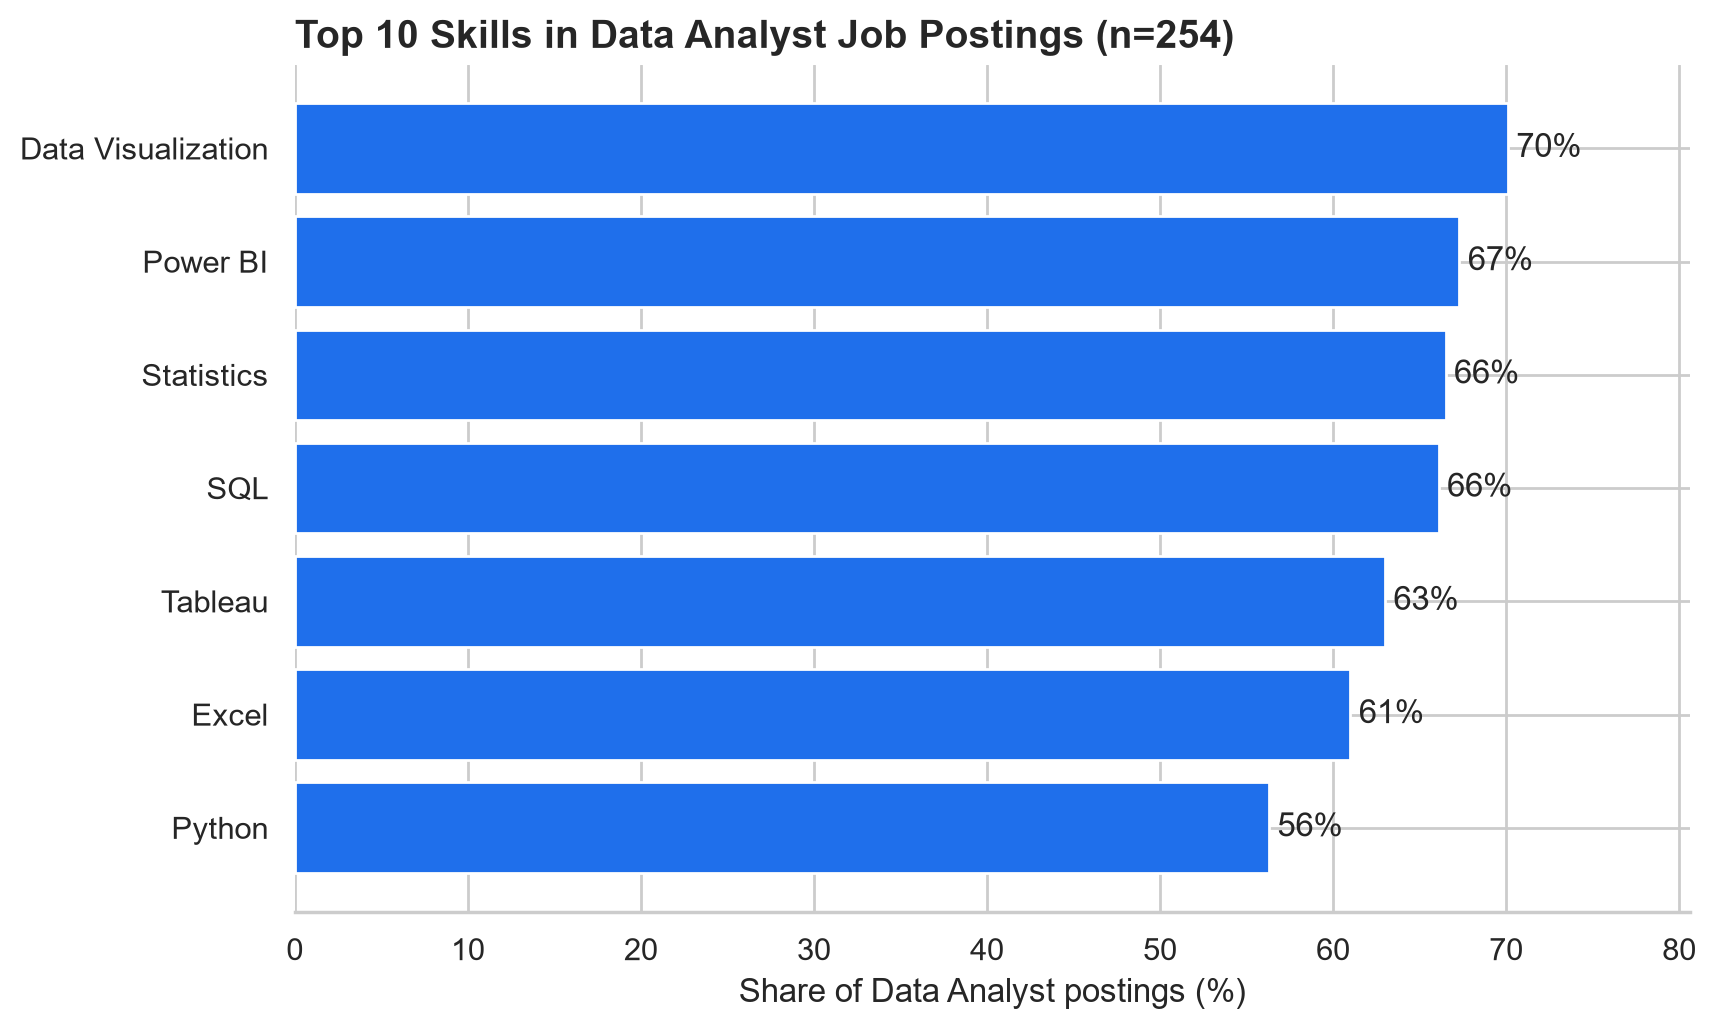

In [4]:
an.plot_top_skills(df)
display(Image(filename=str(an.VIZ_DIR / "top_skills.png")))

### Skills for freshers specifically

In [5]:
fresher_skills = an.skill_demand(fresher_da, 8)
print(f"Fresher Data Analyst postings: n = {len(fresher_da)} (small sample - read as indicative)")
fresher_skills

Fresher Data Analyst postings: n = 46 (small sample - read as indicative)


,skill,postings,pct_of_postings
0,SQL,34,73.9
1,Power BI,33,71.7
2,Statistics,31,67.4
3,Data Visualization,31,67.4
4,Python,30,65.2
5,Tableau,29,63.0
6,Excel,27,58.7


In [6]:
top = fresher_skills.iloc[0]
print(f"Most requested skill in fresher Data Analyst postings: {top['skill']} ({top['pct_of_postings']:.0f}%).")
print("Next four: " + ", ".join(fresher_skills['skill'].iloc[1:5]))

Most requested skill in fresher Data Analyst postings: SQL (74%).
Next four: Power BI, Statistics, Data Visualization, Python


## 4. How does Data Analyst pay grow with experience?
Salaries are in LPA (lakhs per annum). The red diamonds mark the median for *all* tech roles at the same level.

INFO | Saved salary_by_experience.png


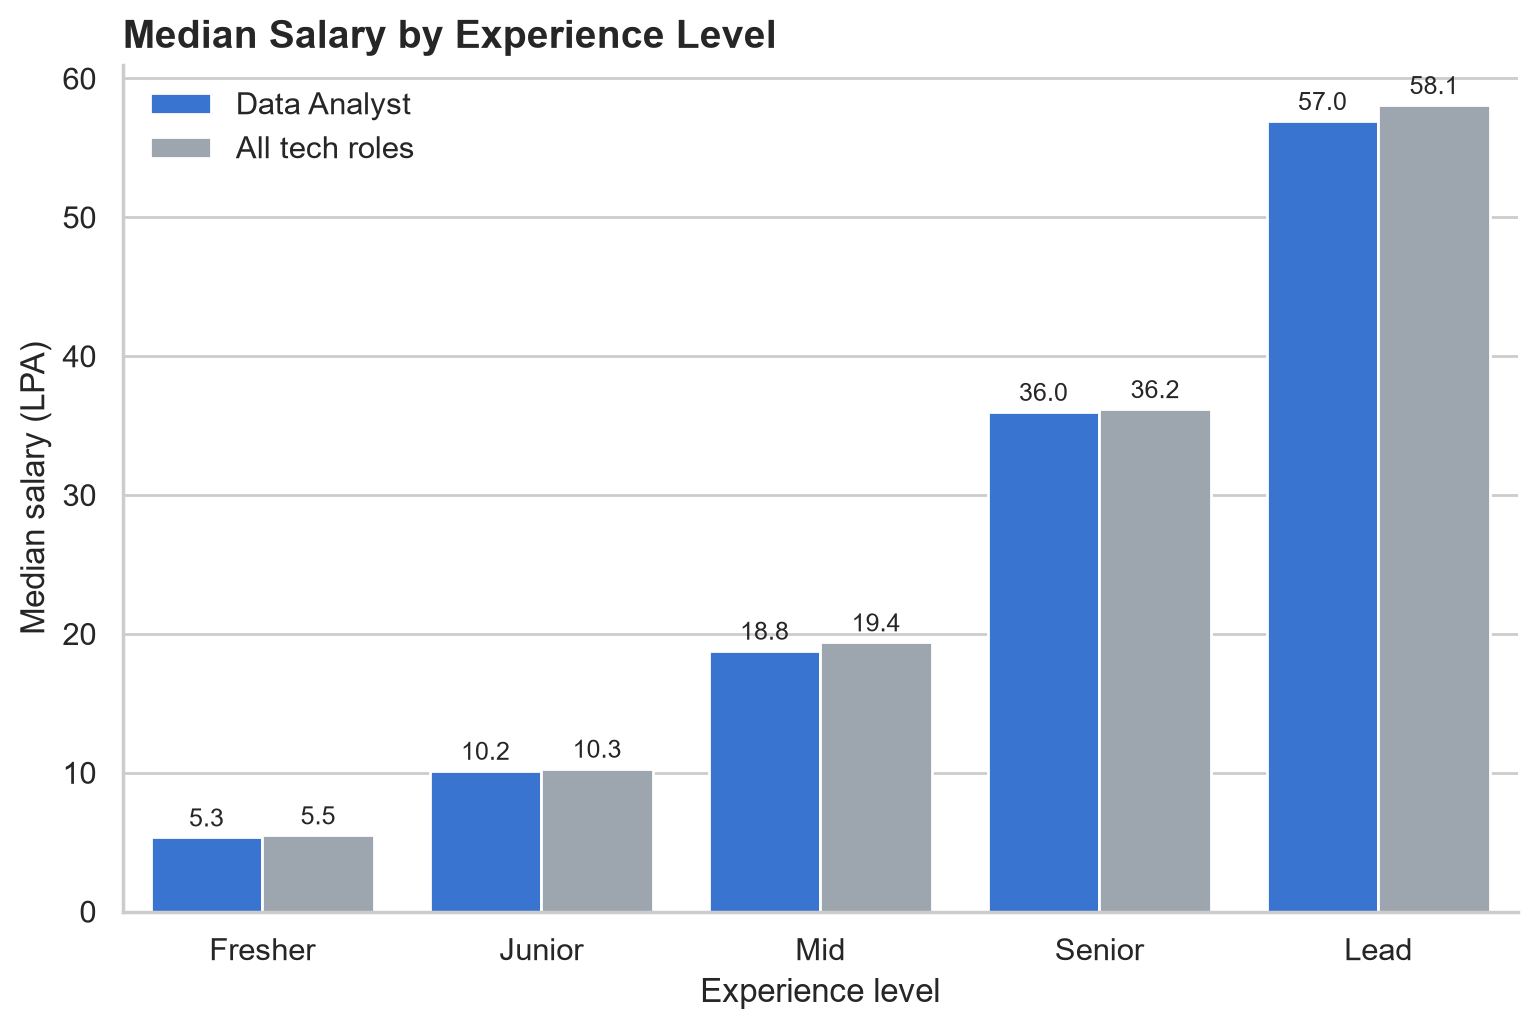

In [7]:
an.plot_salary_by_experience(df)
display(Image(filename=str(an.VIZ_DIR / "salary_by_experience.png")))

In [8]:
an.salary_by_experience(df)

,all_tech_roles,data_analyst,da_postings
experience_group,,,
Fresher,5.5,5.3,46
Junior,10.3,10.2,48
Mid,19.4,18.8,82
Senior,36.2,36.0,46
Lead,58.1,57.0,32


In [9]:
growth = an.salary_by_experience(df)["data_analyst"]
print(f"Median Data Analyst salary rises from {growth['Fresher']:.1f} LPA (Fresher) to {growth['Lead']:.1f} LPA (Lead), "
      f"about {growth['Lead'] / growth['Fresher']:.0f}x.")

Median Data Analyst salary rises from 5.3 LPA (Fresher) to 57.0 LPA (Lead), about 11x.


### Overall salary distribution

INFO | Saved salary_distribution.png


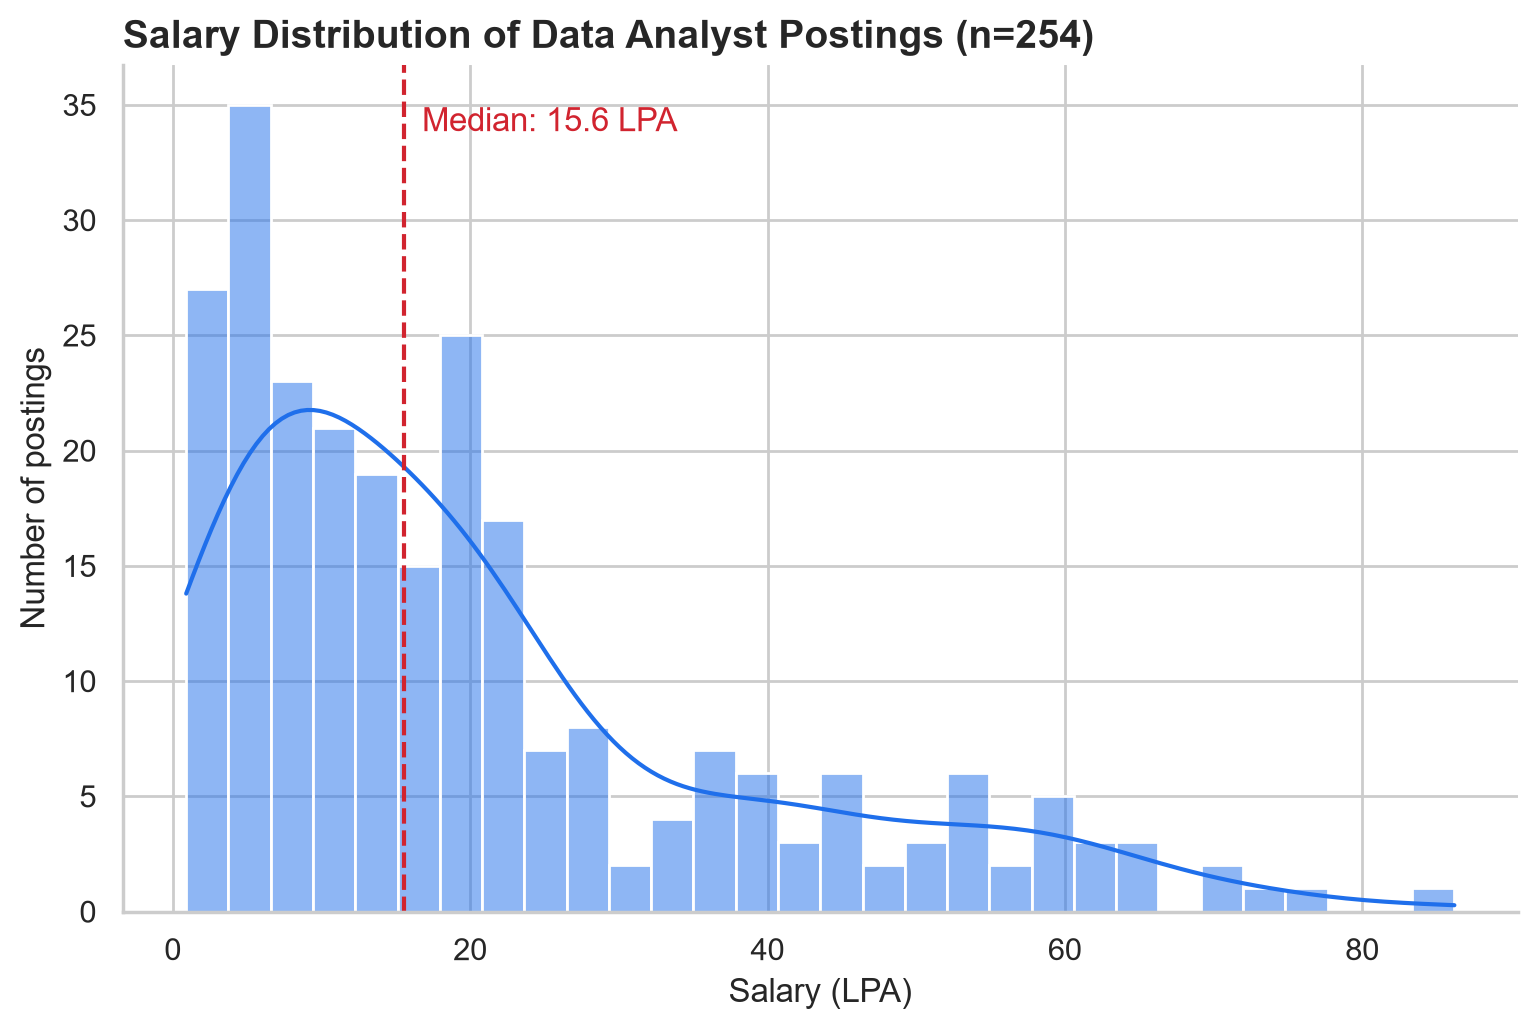

In [10]:
an.plot_salary_distribution(df)
display(Image(filename=str(an.VIZ_DIR / "salary_distribution.png")))

The distribution is right-skewed because it mixes all experience levels, so the **median** is a better summary than the mean, and a single "average Data Analyst salary" is misleading. Salary should always be read *within* an experience level.

## 5. Does a skill actually raise pay?
A naive comparison asks: *do postings that list skill X pay more than postings that don't?* The problem is **confounding**: if a skill is more common in senior postings, it looks well paid only because seniors earn more. Below, the naive comparison is set against an **experience-adjusted** one, where each salary is first expressed as a % above or below the median of its own experience group.

In [11]:
adjusted = an.skill_salary_premium(da)

rows = []
for skill in adjusted["skill"]:
    has = da["skills_list"].map(lambda s: skill in s)
    rows.append({"skill": skill,
                 "naive_diff_LPA": da.loc[has, "salary_lpa"].median() - da.loc[~has, "salary_lpa"].median()})
naive = pd.DataFrame(rows)

comparison = adjusted.merge(naive, on="skill")[
    ["skill", "postings", "naive_diff_LPA", "difference_pct_points"]
].rename(columns={"difference_pct_points": "adjusted_diff_pct_points"})
comparison.head(10)

,skill,postings,naive_diff_LPA,adjusted_diff_pct_points
0,Excel,155,-0.6,1.3
1,Statistics,169,4.6,0.9
2,SQL,168,-4.2,0.3
3,Python,143,-1.0,-0.8
4,Tableau,160,-2.2,-1.3
5,Data Visualization,178,-1.1,-2.0
6,Power BI,171,-2.7,-6.3


In [12]:
max_adj = comparison["adjusted_diff_pct_points"].abs().max()
max_naive = comparison["naive_diff_LPA"].abs().max()
print(f"Naive comparison: differences of up to {max_naive:.1f} LPA appear.")
print(f"After adjusting for experience: no skill moves salary by more than {max_adj:.1f} percentage points.")

Naive comparison: differences of up to 4.6 LPA appear.
After adjusting for experience: no skill moves salary by more than 6.3 percentage points.


**Takeaway:** in this data, skills are not associated with a pay advantage once experience is controlled for. The apparent premiums were seniority effects. Skills decide *whether you are considered*; the data does not show them *increasing the offer*.

## 6. Where are the jobs?

INFO | Saved top_cities.png


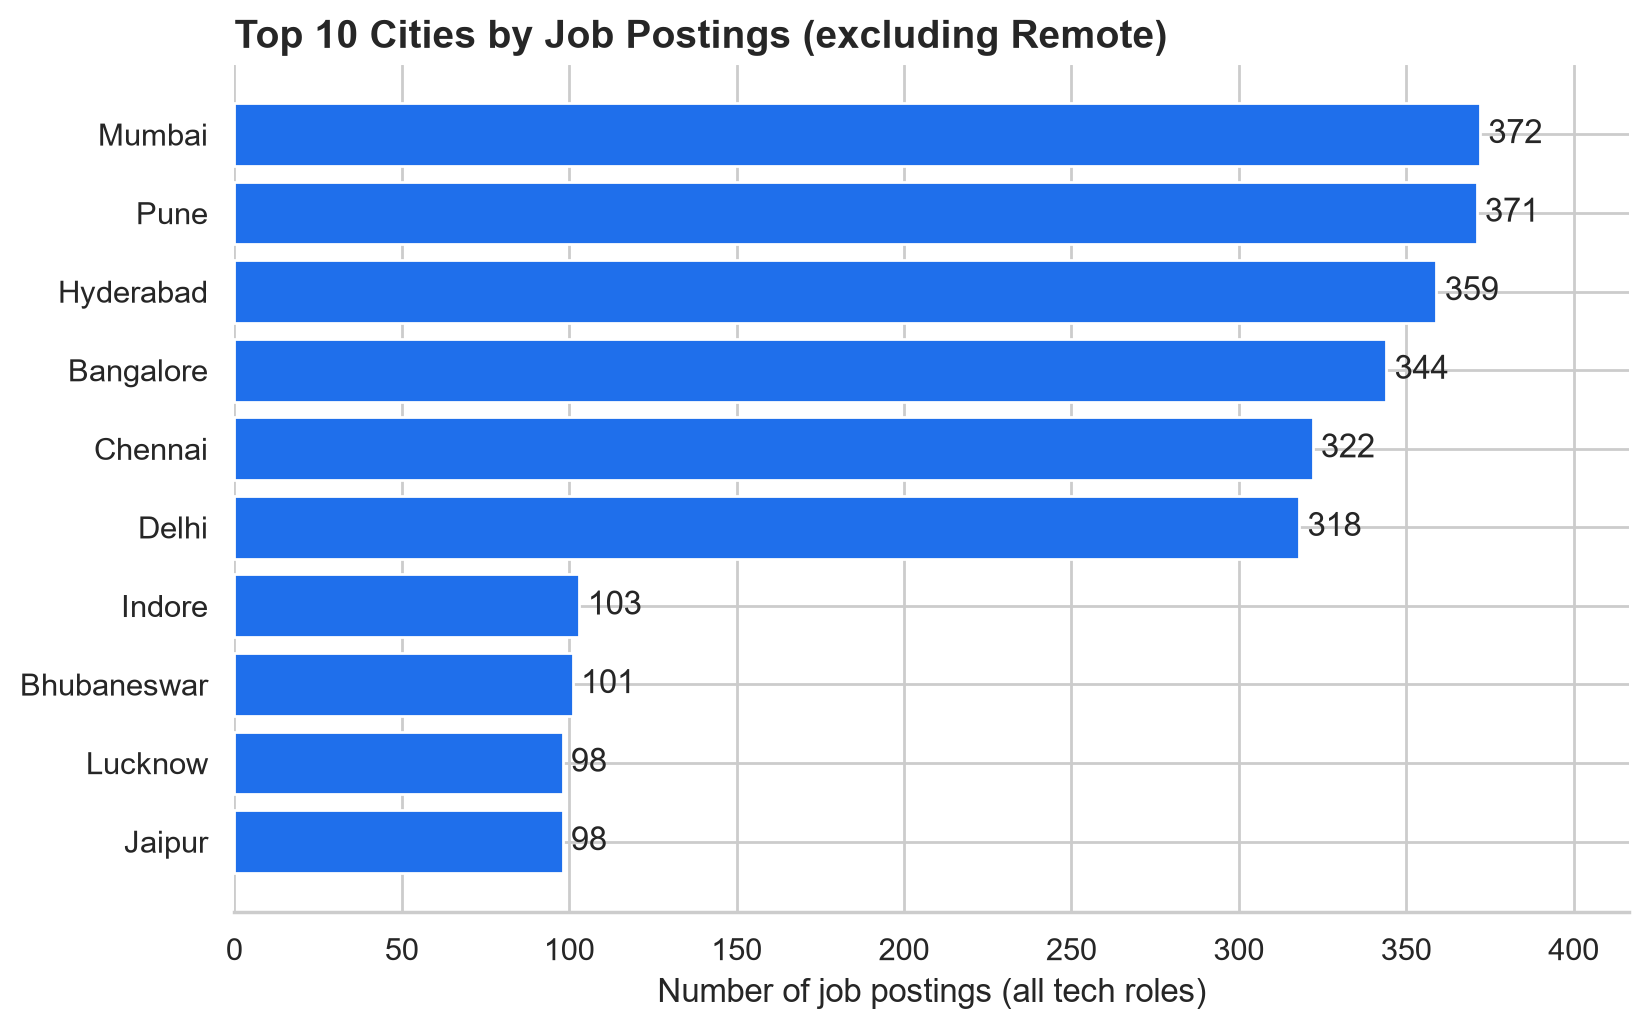

In [13]:
an.plot_top_cities(df)
display(Image(filename=str(an.VIZ_DIR / "top_cities.png")))

In [14]:
cities = an.top_cities(df, 10)
remote_share = (df["city"].str.lower() == "remote").mean() * 100
print(f"Top 5 cities: {', '.join(cities['city'].head(5))} - together {cities['pct_of_postings'].head(5).sum():.0f}% of all postings.")
print(f"Postings listed as 'Remote' (excluded from the city ranking): {remote_share:.1f}%")
print("\nData Analyst work mode split (%):")
print((da["work_mode"].value_counts(normalize=True) * 100).round(1).to_string())

Top 5 cities: Mumbai, Pune, Hyderabad, Bangalore, Chennai - together 35% of all postings.
Postings listed as 'Remote' (excluded from the city ranking): 39.8%

Data Analyst work mode split (%):
work_mode
On-Site   42.5
Hybrid    31.9
Remote    25.6


## 7. How has hiring changed over time?

INFO | Saved monthly_job_trends.png


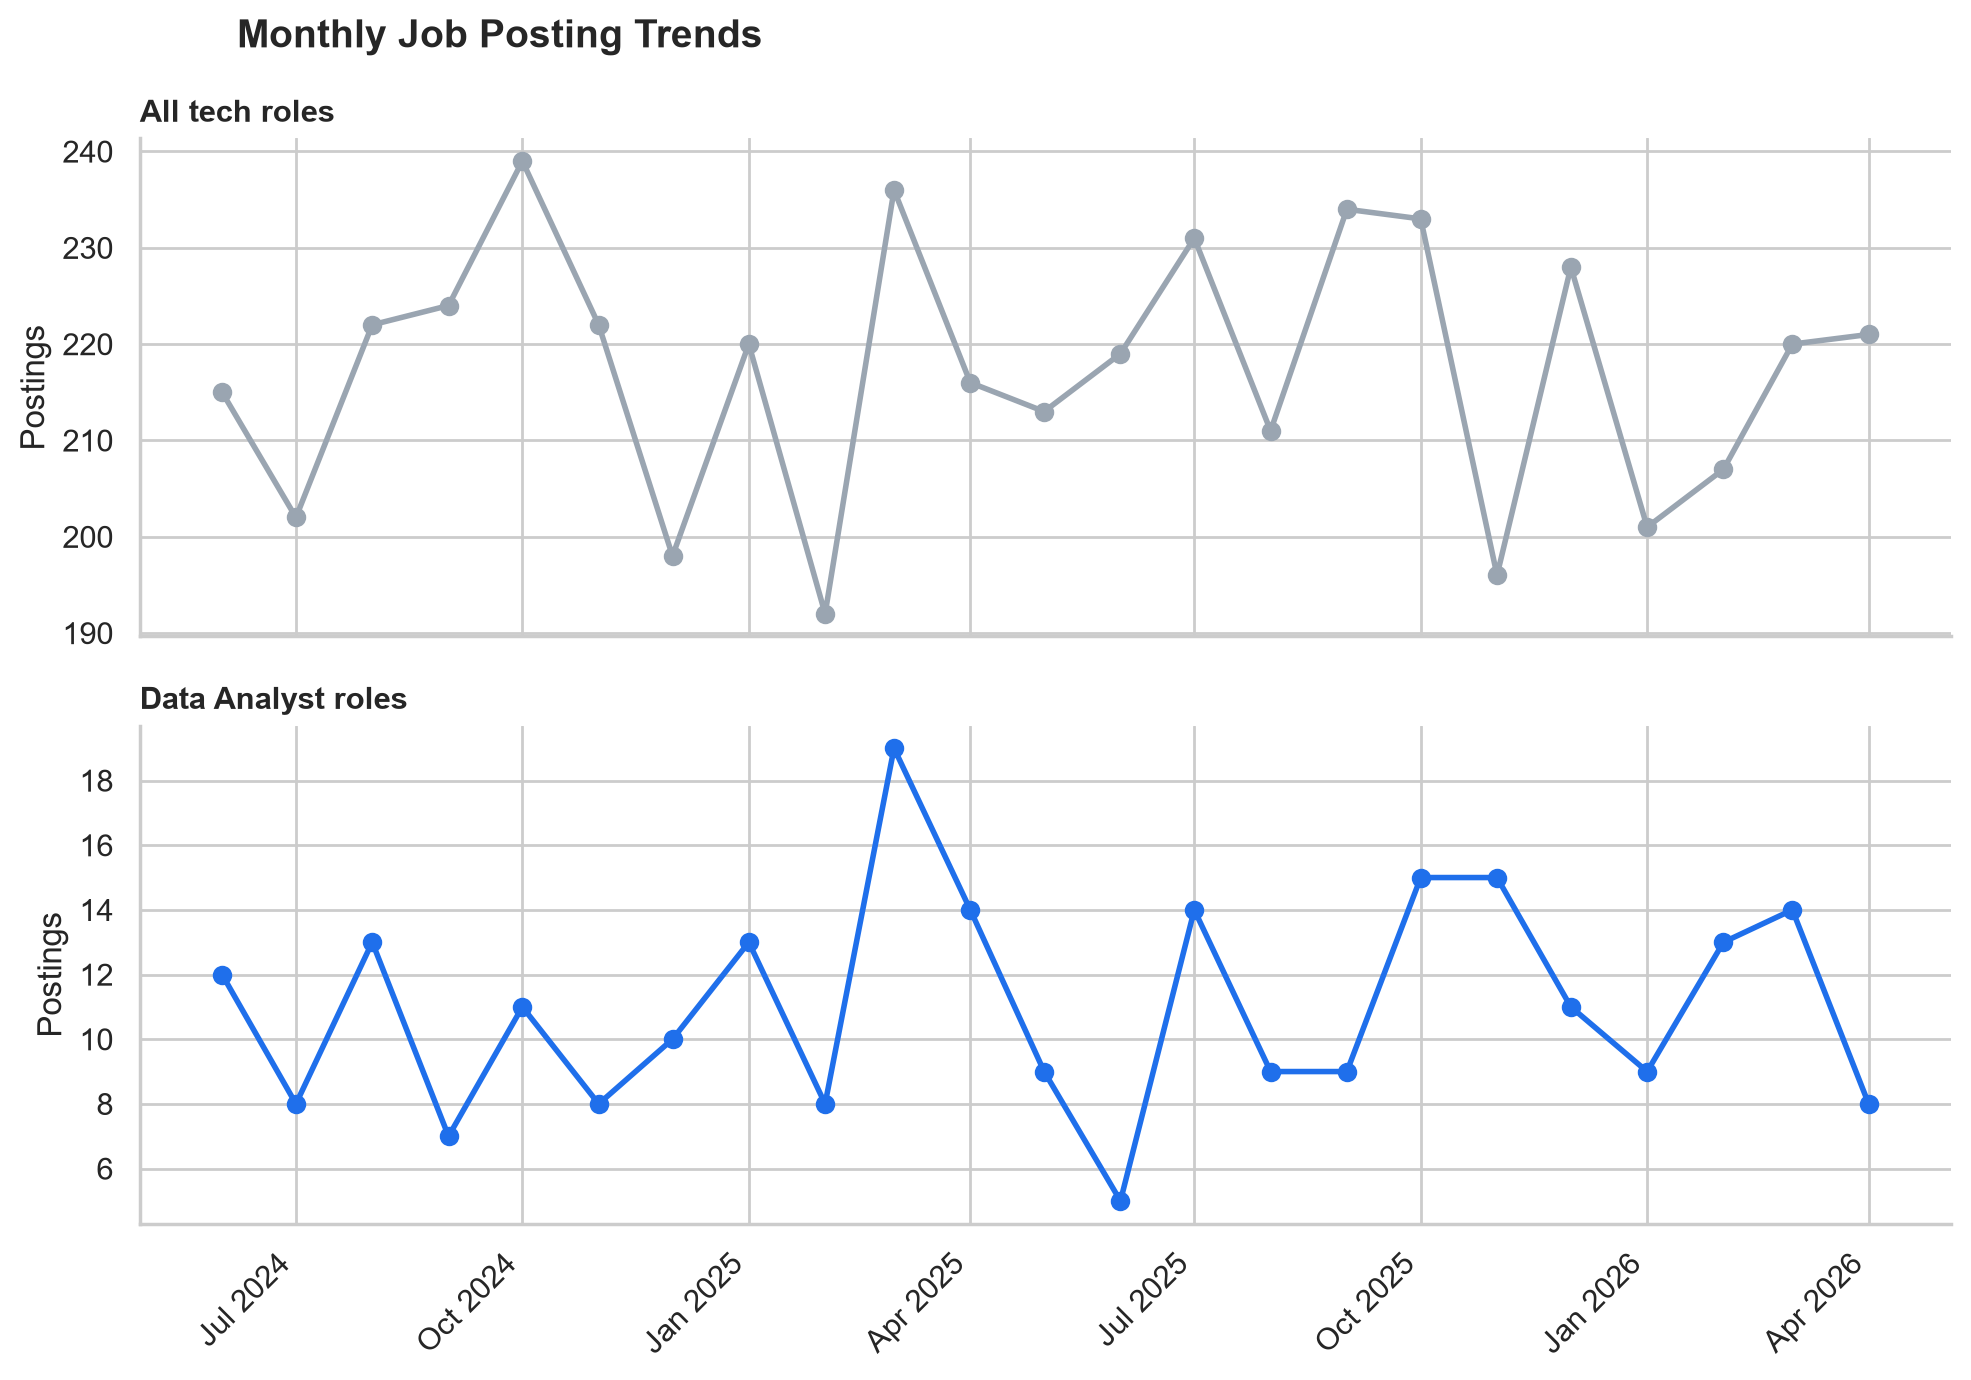

In [15]:
an.plot_monthly_trends(df)
display(Image(filename=str(an.VIZ_DIR / "monthly_job_trends.png")))

In [16]:
trend = an.monthly_trend(df)
peak, low = trend.loc[trend["postings"].idxmax()], trend.loc[trend["postings"].idxmin()]
print(f"Average postings per month: {trend['postings'].mean():.0f}")
print(f"Busiest month: {peak['year_month']} ({peak['postings']} postings)")
print(f"Quietest month: {low['year_month']} ({low['postings']} postings)")
print(f"Busiest vs quietest: {peak['postings'] / low['postings']:.2f}x")

Average postings per month: 217
Busiest month: 2024-10 (239 postings)
Quietest month: 2025-02 (192 postings)
Busiest vs quietest: 1.24x


## 8. How competitive are the postings?
Competition is measured as **applicants per opening** (applicants ÷ openings).

In [17]:
comp = an.competition_by_experience(df)
comp["postings"] = da.groupby("experience_group", observed=True).size().values
print(f"Median applicants per opening - Data Analyst: {da['applicants_per_opening'].median():.1f} | "
      f"all roles: {df['applicants_per_opening'].median():.1f}")
comp

Median applicants per opening - Data Analyst: 88.8 | all roles: 87.8


,experience_group,median_applicants_per_opening,postings
0,Fresher,89.3,46
1,Junior,92.6,48
2,Mid,84.2,82
3,Senior,94.0,46
4,Lead,93.8,32


## 9. Limitations (read before drawing conclusions)

Several checks suggest this dataset is **synthetic or heavily simulated** rather than scraped from real postings. The cell below quantifies them.

In [18]:
sal = an.salary_by_experience(df)
gap_pct = ((sal["data_analyst"] - sal["all_tech_roles"]) / sal["all_tech_roles"] * 100).abs().max()
spread = an.skill_demand(da, 5)["pct_of_postings"]

print(f"1. Data Analyst median salary is within {gap_pct:.0f}% of the all-roles median at every experience level.")
print(f"2. Applicants per opening: {da['applicants_per_opening'].median():.1f} (Data Analyst) vs "
      f"{df['applicants_per_opening'].median():.1f} (all roles) - almost no difference between roles.")
print(f"3. The top-5 Data Analyst skills all sit between {spread.min():.0f}% and {spread.max():.0f}%, an unusually even spread.")
print("4. Records contain implausible combinations (e.g. a government PSU listed under EdTech).")

1. Data Analyst median salary is within 3% of the all-roles median at every experience level.
2. Applicants per opening: 88.8 (Data Analyst) vs 87.8 (all roles) - almost no difference between roles.
3. The top-5 Data Analyst skills all sit between 63% and 70%, an unusually even spread.
4. Records contain implausible combinations (e.g. a government PSU listed under EdTech).


**What this means**

- Findings describe *this dataset*, not the real Indian job market. Statements such as "Data Analysts earn the same as other tech roles" are properties of the data, not market insights.
- Fresher Data Analyst results rest on only 46 postings.
- The dataset has no information on company-specific hiring practices, skill levels required, or actual offers made.
- The value of the project is the **method**: a reproducible cleaning pipeline, confounding-aware analysis, and transparent reporting of sample sizes and limitations. The same code can be re-run on a real scraped dataset.

## 10. Conclusions and recommendations for a fresher

1. **Learn SQL first.** It is the most requested skill in fresher Data Analyst postings (about three in four), followed by Power BI, Statistics, Data Visualization and Python.
2. **A BI tool plus SQL covers most of the demand.** Power BI and Data Visualization appear in roughly two-thirds or more of postings; pair them with portfolio dashboards.
3. **Expect about 5-5.5 LPA at the fresher level**, rising roughly tenfold toward Lead roles; the path matters more than any single skill.
4. **Do not expect a skill to raise your offer on its own** (Section 5). Use skills to qualify for more postings, and use experience to move up the pay scale.
5. **Target hub cities, but consider remote and hybrid roles**: they account for a large part of Data Analyst postings.
6. **Applications are crowded (~85-90 applicants per opening)**, so a project portfolio and clear evidence of skills are what differentiate.

*Next steps: repeat the analysis on a scraped, real dataset; widen the definition to include Business and BI Analyst titles; add a statistical test for the salary comparisons.*